<a href="https://colab.research.google.com/github/govardhanmudumbai-cmyk/Zepto-Capstone/blob/main/Neural_Network_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import seaborn as sns
import pandas as pd

# Load Titanic dataset
df = sns.load_dataset("titanic")

# Save the offline copy
df.to_csv("titanic.csv", index=False)

print("Saved successfully!")
print("Shape:", df.shape)
print("File exists:", __import__("os").path.exists("titanic.csv"))

display(df.head())

Saved successfully!
Shape: (891, 15)
File exists: True


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [1]:
import pandas as pd

print("=== CLASSIFICATION MODELS EVALUATION METRICS ===")
try:
    class_df = pd.read_csv("outputs/classification_results.csv")
    display(class_df)
except FileNotFoundError:
    print("Classification results CSV file not found. Please run the modeling pipeline cell first.")

print("\n=== REGRESSION MODEL EVALUATION METRICS (Predicting Fare) ===")
try:
    reg_df = pd.read_csv("outputs/regression_results.csv")
    display(reg_df)
except FileNotFoundError:
    print("Regression results CSV file not found. Please run the modeling pipeline cell first.")

=== CLASSIFICATION MODELS EVALUATION METRICS ===
Classification results CSV file not found. Please run the modeling pipeline cell first.

=== REGRESSION MODEL EVALUATION METRICS (Predicting Fare) ===
Regression results CSV file not found. Please run the modeling pipeline cell first.


In [ ]:
import pandas as pd
import os

print("File exists:", os.path.exists("titanic.csv"))

df_check = pd.read_csv("titanic.csv")

print("Shape:", df_check.shape)
print("Columns:")
print(df_check.columns.tolist())

display(df_check.head())

File exists: True
Shape: (891, 15)
Columns:
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [ ]:
from google.colab import files

files.download("titanic.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

STEP 1 — LOADING CLEANED TITANIC DATA
Dataset shape: (891, 15)
Columns:
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True



STEP 2 — CLASS BALANCE


,Class,Count,Percentage
0,Not Survived (0),549,61.62
1,Survived (1),342,38.38


Stratification is used because the survival classes are not perfectly balanced. It preserves approximately the same class proportions in both training and testing data.

STEP 3 — STRATIFIED TRAIN / TEST SPLIT
Training shape: (712, 14)
Testing shape: (179, 14)

Original class proportions:


,proportion
survived,
0,0.616162
1,0.383838


... (3 outputs left out)

,proportion
survived,
0,0.614525
1,0.385475



STEP 4 — MODEL FEATURES
Numeric features:
['pclass', 'age', 'sibsp', 'parch', 'fare']

Categorical features:
['sex', 'embarked']

Redundant/leaky fields such as alive, class, adult_male, alone and embark_town are excluded.

STEP 5 — PREPROCESSING
Numeric:
  Median imputation -> StandardScaler

Categorical:
  Most-frequent imputation -> OneHotEncoder

All preprocessing is contained inside the model Pipeline, so it is fitted only on the training split.

STEP 6 — TRAIN THREE CLASSIFIERS
✓ Logistic Regression trained
✓ Decision Tree trained
✓ Random Forest trained

STEP 7 — CLASSIFICATION METRICS


,Model,Accuracy,Precision,Recall,F1,AUC
0,Logistic Regression,0.8045,0.7931,0.6667,0.7244,0.8437
1,Decision Tree,0.7654,0.7547,0.5797,0.6557,0.7971
2,Random Forest,0.8156,0.8000,0.6957,0.7442,0.8300



STEP 8 — CONFUSION MATRICES AND ROC


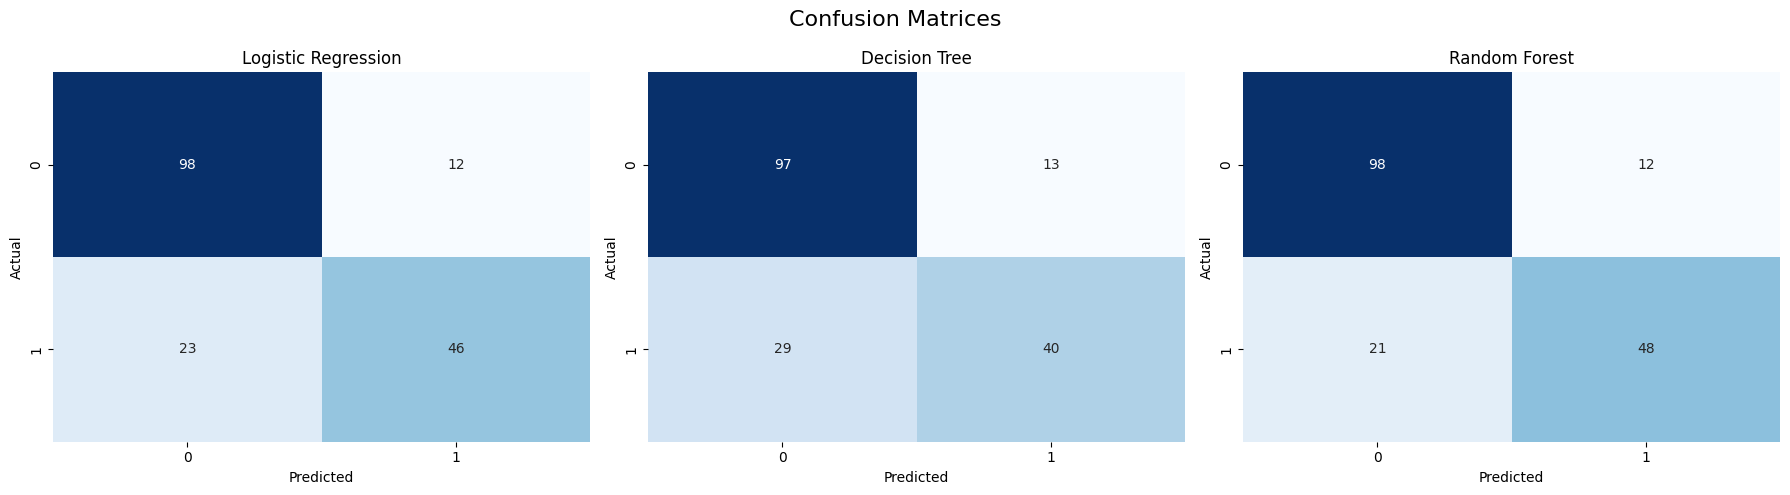

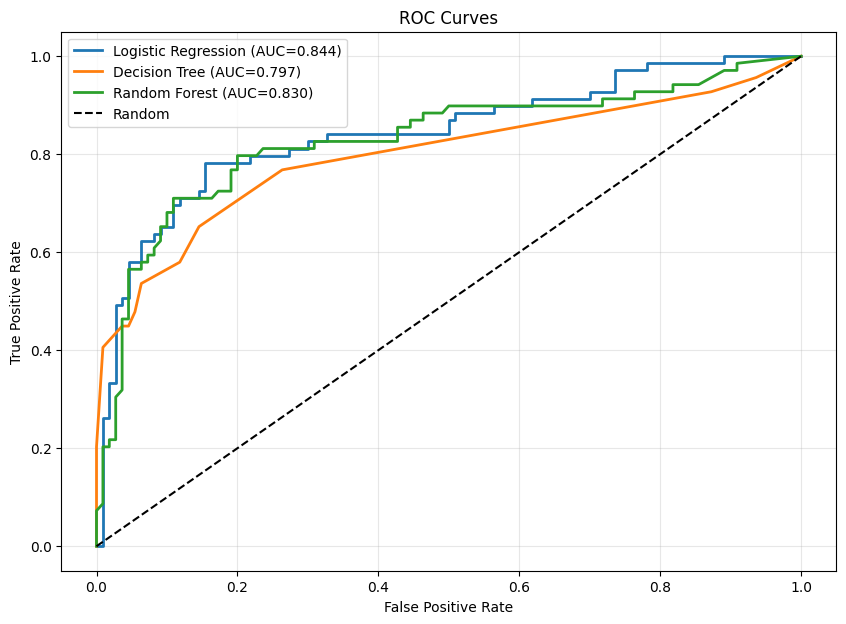


STEP 9 — DECISION TREE VISUALIZATION


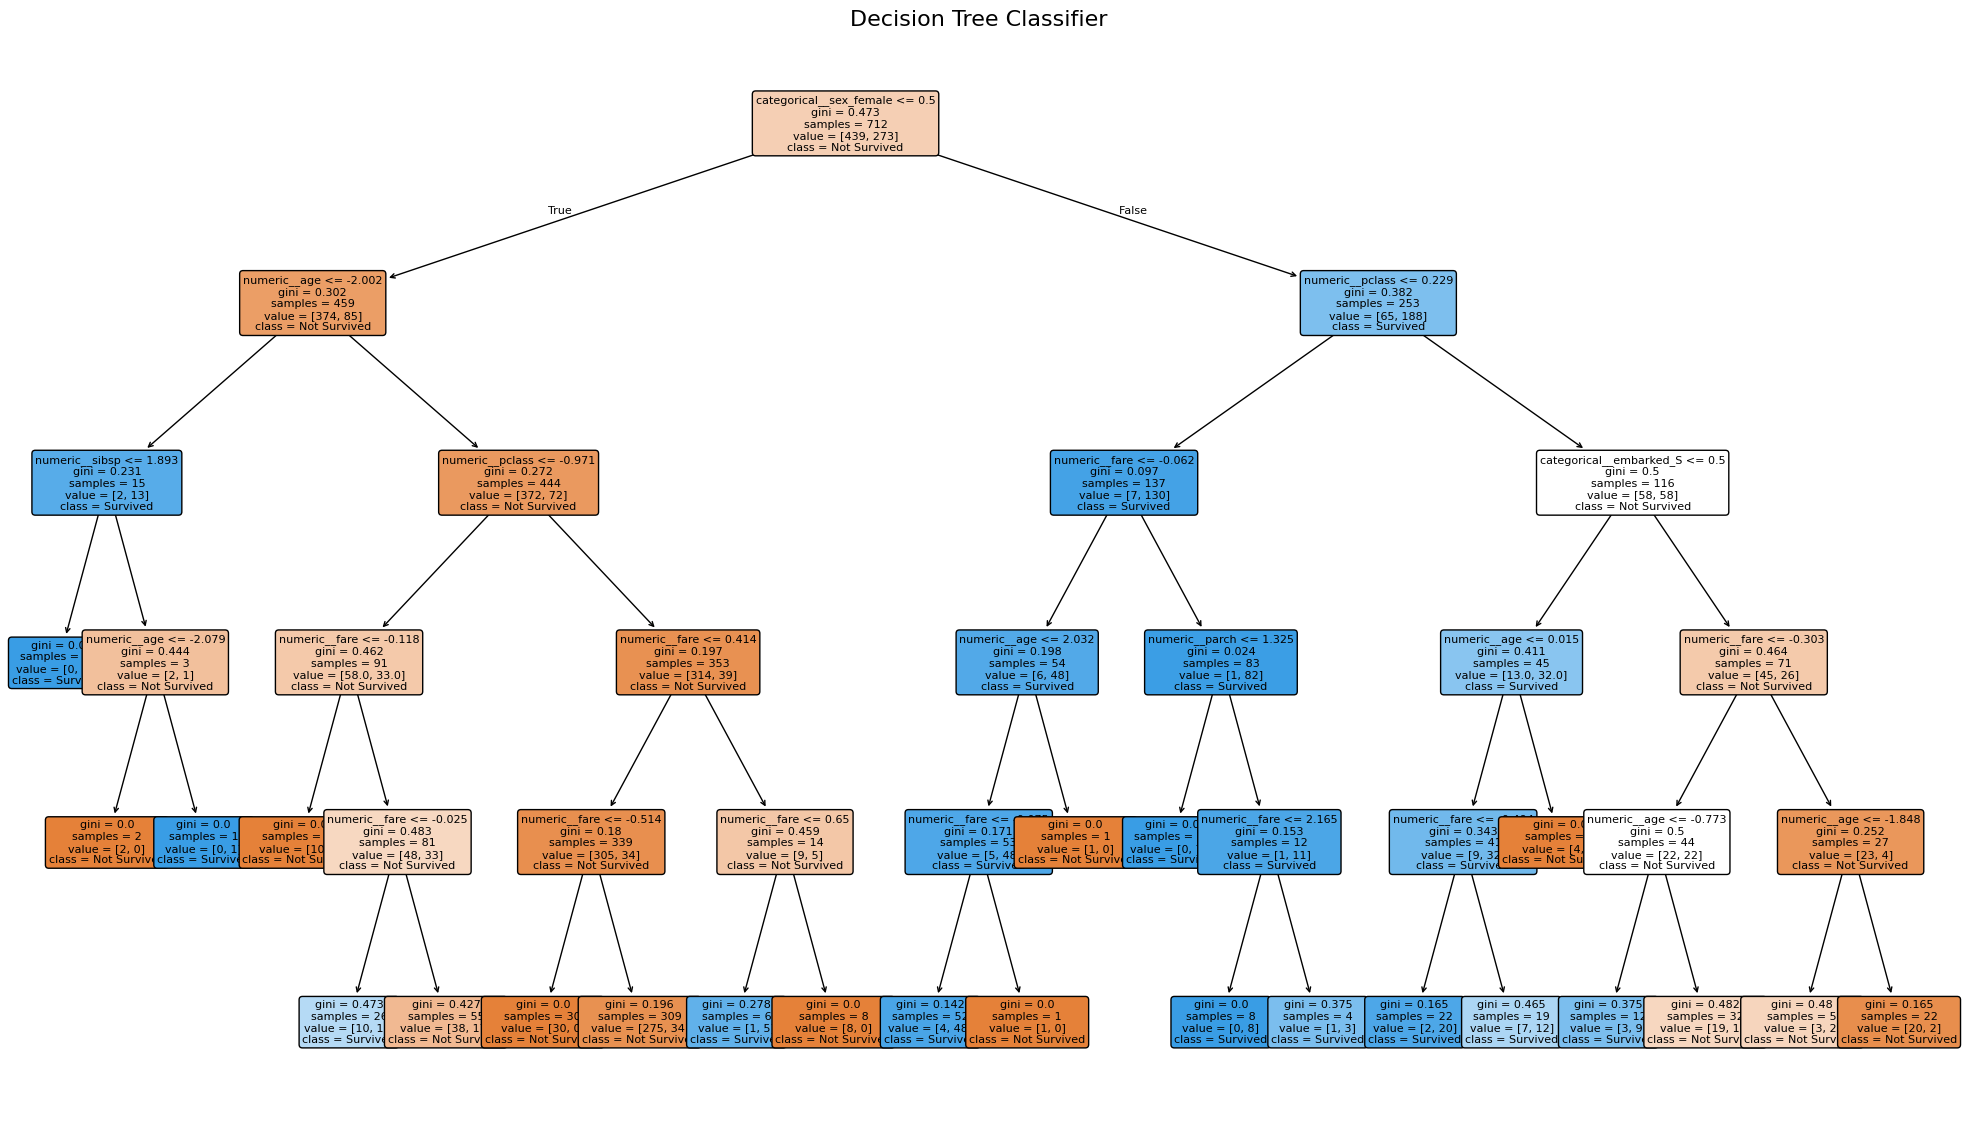


STEP 10 — IMBALANCE COMPARISON


,Strategy,Precision,Recall,F1
0,Baseline,0.7931,0.6667,0.7244
1,Class Weight Balanced,0.7297,0.7826,0.7552
2,SMOTE,0.7397,0.7826,0.7606



Best imbalance strategy by F1: SMOTE

STEP 11 — RANDOM FOREST GRIDSEARCH
Running GridSearchCV...

Best parameters:
{'model__max_depth': 5, 'model__max_features': 'sqrt', 'model__n_estimators': 100}

Best CV F1: 0.7459

OOB score: 0.8272


,model__max_depth,model__max_features,model__n_estimators,best_cv_f1,oob_score
0,5,sqrt,100,0.7459,0.8272



STEP 12 — LINEAR REGRESSION
Linear regression trained successfully.

STEP 13 — REGRESSION METRICS


,Metric,Value
0,MAE,20.8977
1,RMSE,30.5328
2,R2,0.3975
3,Adjusted R2,0.3617



STEP 14 — RESIDUAL ANALYSIS


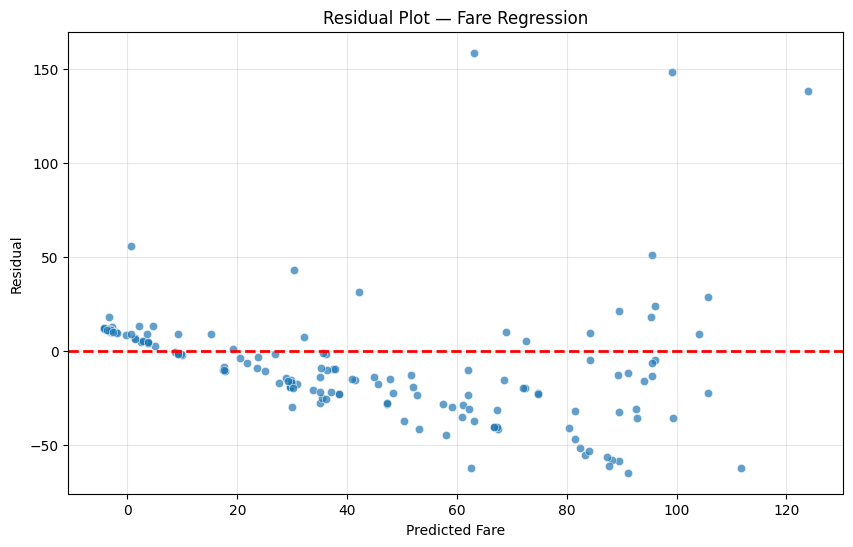

Correlation between predicted fare and absolute residuals: 0.5456

Heteroscedasticity conclusion:
The residual plot provides evidence of heteroscedasticity because the magnitude of residuals changes noticeably with predicted fare.

STEP 15 — FINAL MODEL COMPARISON
Best classifier based on F1: Random Forest

CLASSIFICATION MODELS


,Model,Accuracy,Precision,Recall,F1,AUC
0,Logistic Regression,0.8045,0.7931,0.6667,0.7244,0.8437
1,Decision Tree,0.7654,0.7547,0.5797,0.6557,0.7971
2,Random Forest,0.8156,0.8000,0.6957,0.7442,0.8300



REGRESSION MODEL


,Regression Model,MAE,RMSE,R2,Adjusted R2
0,Linear Regression,20.8977,30.5328,0.3975,0.3617


,Model Type,Model,Accuracy,Precision,Recall,F1,AUC,MAE,RMSE,R2,Adjusted R2
0,Classification,Logistic Regression,0.8045,0.7931,0.6667,0.7244,0.8437,NaN,NaN,NaN,NaN
1,Classification,Decision Tree,0.7654,0.7547,0.5797,0.6557,0.7971,NaN,NaN,NaN,NaN
2,Classification,Random Forest,0.8156,0.8000,0.6957,0.7442,0.8300,NaN,NaN,NaN,NaN
3,Regression,Linear Regression,NaN,NaN,NaN,NaN,NaN,20.8977,30.5328,0.3975,0.3617



FINAL WRITTEN RECOMMENDATION
----------------------------------------------------------------------

I would deploy the Random Forest classifier for the
Titanic survival prediction task. It achieved an F1 score of
0.744, accuracy of 0.816, precision of
0.800, recall of 0.696, and AUC of
0.830. The F1 score is useful because it balances
precision and recall rather than relying only on accuracy.
The final deployment decision should also consider whether
false positives or false negatives carry a greater practical cost.


STEP 16 — SAVE COMPLETE PIPELINE
Complete pipeline saved to: model_artifacts/best_titanic_pipeline.joblib
✓ Pipeline successfully reloaded.

Raw input:


,pclass,age,sibsp,parch,fare,sex,embarked
565,3,24.0,2,0,24.15,male,S


Predicted class: 0
Predicted survival probability: 0.155

✓ Reloaded pipeline successfully predicts from raw input.

🎉 MODULE 2 MODELING PIPELINE FINISHED

Generated files:
✓ outputs/classification_results.csv
✓ outputs/imbalance_comparison.csv
✓ outputs/regression_results.csv
✓ outputs/model_comparison.csv
✓ outputs/gridsearch_best_params.csv
✓ outputs/model_summary.txt
✓ model_artifacts/best_titanic_pipeline.joblib

All 16 modeling steps completed.


In [ ]:
# ============================================================
# ZEPTO CAPSTONE — MODULE 2
# 02_modeling.ipynb
# COMPLETE MODELING PIPELINE
# ============================================================

!pip install -q imbalanced-learn joblib

import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_curve,
    roc_auc_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

os.makedirs("outputs", exist_ok=True)
os.makedirs("model_artifacts", exist_ok=True)


# ============================================================
# STEP 1 — LOAD CLEANED TITANIC DATA
# ============================================================

print("=" * 80)
print("STEP 1 — LOADING CLEANED TITANIC DATA")
print("=" * 80)

if not os.path.exists("titanic.csv"):
    raise FileNotFoundError(
        "titanic.csv not found. Upload titanic.csv to Colab first."
    )

df = pd.read_csv("titanic.csv")

print("Dataset shape:", df.shape)
print("Columns:")
print(df.columns.tolist())

display(df.head())


# ============================================================
# STEP 2 — CLASS BALANCE
# ============================================================

print("\n" + "=" * 80)
print("STEP 2 — CLASS BALANCE")
print("=" * 80)

class_counts = df["survived"].value_counts().sort_index()
class_percent = (
    df["survived"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

class_balance = pd.DataFrame({
    "Class": [
        "Not Survived (0)",
        "Survived (1)"
    ],
    "Count": class_counts.values,
    "Percentage": class_percent.round(2).values
})

display(class_balance)

print(
    "Stratification is used because the survival classes are not "
    "perfectly balanced. It preserves approximately the same class "
    "proportions in both training and testing data."
)


# ============================================================
# STEP 3 — STRATIFIED TRAIN / TEST SPLIT
# ============================================================

print("\n" + "=" * 80)
print("STEP 3 — STRATIFIED TRAIN / TEST SPLIT")
print("=" * 80)

X = df.drop(columns=["survived"])
y = df["survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nOriginal class proportions:")
display(y.value_counts(normalize=True).sort_index())

print("\nTraining class proportions:")
display(y_train.value_counts(normalize=True).sort_index())

print("\nTesting class proportions:")
display(y_test.value_counts(normalize=True).sort_index())


# ============================================================
# STEP 4 — MODEL FEATURES
# ============================================================

print("\n" + "=" * 80)
print("STEP 4 — MODEL FEATURES")
print("=" * 80)

numeric_features = [
    "pclass",
    "age",
    "sibsp",
    "parch",
    "fare"
]

categorical_features = [
    "sex",
    "embarked"
]

model_features = (
    numeric_features +
    categorical_features
)

X_train_model = X_train[model_features].copy()
X_test_model = X_test[model_features].copy()

print("Numeric features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

print(
    "\nRedundant/leaky fields such as alive, class, adult_male, "
    "alone and embark_town are excluded."
)


# ============================================================
# STEP 5 — PREPROCESSING
# ============================================================

print("\n" + "=" * 80)
print("STEP 5 — PREPROCESSING")
print("=" * 80)

numeric_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    )
])

categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    )
])

preprocessor = ColumnTransformer([
    (
        "numeric",
        numeric_pipeline,
        numeric_features
    ),
    (
        "categorical",
        categorical_pipeline,
        categorical_features
    )
])

print("Numeric:")
print("  Median imputation -> StandardScaler")

print("\nCategorical:")
print("  Most-frequent imputation -> OneHotEncoder")

print(
    "\nAll preprocessing is contained inside the model Pipeline, "
    "so it is fitted only on the training split."
)


# ============================================================
# STEP 6 — TRAIN THREE CLASSIFIERS
# ============================================================

print("\n" + "=" * 80)
print("STEP 6 — TRAIN THREE CLASSIFIERS")
print("=" * 80)

models = {

    "Logistic Regression":
        LogisticRegression(
            max_iter=1000,
            random_state=42
        ),

    "Decision Tree":
        DecisionTreeClassifier(
            max_depth=5,
            random_state=42
        ),

    "Random Forest":
        RandomForestClassifier(
            n_estimators=200,
            random_state=42
        )
}

fitted_models = {}
predictions = {}
probabilities = {}

for name, model in models.items():

    pipeline = Pipeline([
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            model
        )
    ])

    pipeline.fit(
        X_train_model,
        y_train
    )

    fitted_models[name] = pipeline

    predictions[name] = pipeline.predict(
        X_test_model
    )

    probabilities[name] = pipeline.predict_proba(
        X_test_model
    )[:, 1]

    print("✓", name, "trained")


# ============================================================
# STEP 7 — EVALUATION METRICS
# ============================================================

print("\n" + "=" * 80)
print("STEP 7 — CLASSIFICATION METRICS")
print("=" * 80)

classification_results = []

for name in models.keys():

    y_pred = predictions[name]
    y_prob = probabilities[name]

    classification_results.append({

        "Model": name,

        "Accuracy":
            accuracy_score(
                y_test,
                y_pred
            ),

        "Precision":
            precision_score(
                y_test,
                y_pred
            ),

        "Recall":
            recall_score(
                y_test,
                y_pred
            ),

        "F1":
            f1_score(
                y_test,
                y_pred
            ),

        "AUC":
            roc_auc_score(
                y_test,
                y_prob
            )
    })

classification_results_df = pd.DataFrame(
    classification_results
)

display(
    classification_results_df.round(4)
)

classification_results_df.to_csv(
    "outputs/classification_results.csv",
    index=False
)


# ============================================================
# STEP 8 — CONFUSION MATRICES + ROC
# ============================================================

print("\n" + "=" * 80)
print("STEP 8 — CONFUSION MATRICES AND ROC")
print("=" * 80)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5)
)

for ax, name in zip(
    axes,
    models.keys()
):

    cm = confusion_matrix(
        y_test,
        predictions[name]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.suptitle(
    "Confusion Matrices",
    fontsize=16
)

plt.tight_layout()
plt.show()


# ROC curves

plt.figure(figsize=(10, 7))

for name in models.keys():

    fpr, tpr, _ = roc_curve(
        y_test,
        probabilities[name]
    )

    auc_value = roc_auc_score(
        y_test,
        probabilities[name]
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC={auc_value:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    label="Random"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# ============================================================
# STEP 9 — DECISION TREE VISUALIZATION
# ============================================================

print("\n" + "=" * 80)
print("STEP 9 — DECISION TREE VISUALIZATION")
print("=" * 80)

tree_pipeline = fitted_models[
    "Decision Tree"
]

tree_model = tree_pipeline.named_steps[
    "model"
]

feature_names = (
    tree_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

plt.figure(
    figsize=(25, 14)
)

plot_tree(
    tree_model,
    feature_names=feature_names,
    class_names=[
        "Not Survived",
        "Survived"
    ],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title(
    "Decision Tree Classifier",
    fontsize=16
)

plt.show()


# ============================================================
# STEP 10 — IMBALANCE COMPARISON
# ============================================================

print("\n" + "=" * 80)
print("STEP 10 — IMBALANCE COMPARISON")
print("=" * 80)


# ---------- BASELINE ----------

baseline_pipeline = Pipeline([
    (
        "preprocessor",
        preprocessor
    ),
    (
        "model",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
])

baseline_pipeline.fit(
    X_train_model,
    y_train
)

baseline_pred = baseline_pipeline.predict(
    X_test_model
)


# ---------- CLASS WEIGHT ----------

balanced_pipeline = Pipeline([
    (
        "preprocessor",
        preprocessor
    ),
    (
        "model",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    )
])

balanced_pipeline.fit(
    X_train_model,
    y_train
)

balanced_pred = balanced_pipeline.predict(
    X_test_model
)


# ---------- SMOTE ----------

smote_pipeline = ImbPipeline([
    (
        "preprocessor",
        preprocessor
    ),
    (
        "smote",
        SMOTE(
            random_state=42
        )
    ),
    (
        "model",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
])

smote_pipeline.fit(
    X_train_model,
    y_train
)

smote_pred = smote_pipeline.predict(
    X_test_model
)


# ---------- COMPARE ----------

imbalance_results = []

for strategy, pred in [

    ("Baseline", baseline_pred),

    (
        "Class Weight Balanced",
        balanced_pred
    ),

    ("SMOTE", smote_pred)
]:

    imbalance_results.append({

        "Strategy": strategy,

        "Precision":
            precision_score(
                y_test,
                pred
            ),

        "Recall":
            recall_score(
                y_test,
                pred
            ),

        "F1":
            f1_score(
                y_test,
                pred
            )
    })

imbalance_results_df = pd.DataFrame(
    imbalance_results
)

display(
    imbalance_results_df.round(4)
)

imbalance_results_df.to_csv(
    "outputs/imbalance_comparison.csv",
    index=False
)

best_imbalance = (
    imbalance_results_df
    .sort_values(
        "F1",
        ascending=False
    )
    .iloc[0]
)

print(
    "\nBest imbalance strategy by F1:",
    best_imbalance["Strategy"]
)


# ============================================================
# STEP 11 — RANDOM FOREST GRIDSEARCH + OOB
# ============================================================

print("\n" + "=" * 80)
print("STEP 11 — RANDOM FOREST GRIDSEARCH")
print("=" * 80)

rf_pipeline = Pipeline([
    (
        "preprocessor",
        preprocessor
    ),
    (
        "model",
        RandomForestClassifier(
            oob_score=True,
            random_state=42
        )
    )
])

param_grid = {

    "model__n_estimators": [
        100,
        200
    ],

    "model__max_depth": [
        None,
        5,
        10
    ],

    "model__max_features": [
        "sqrt",
        "log2"
    ]
}

print("Running GridSearchCV...")

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid_search.fit(
    X_train_model,
    y_train
)

print("\nBest parameters:")
print(grid_search.best_params_)

print(
    "\nBest CV F1:",
    round(
        grid_search.best_score_,
        4
    )
)

best_rf_pipeline = (
    grid_search.best_estimator_
)

best_rf_model = (
    best_rf_pipeline
    .named_steps["model"]
)

print(
    "\nOOB score:",
    round(
        best_rf_model.oob_score_,
        4
    )
)

# IMPORTANT:
# best_params_ has ONE underscore at the end.

gridsearch_results = pd.DataFrame([
    {

        **grid_search.best_params_,

        "best_cv_f1":
            grid_search.best_score_,

        "oob_score":
            best_rf_model.oob_score_
    }
])

display(
    gridsearch_results.round(4)
)

gridsearch_results.to_csv(
    "outputs/gridsearch_best_params.csv",
    index=False
)


# ============================================================
# STEP 12 — REGRESSION: PREDICT FARE
# ============================================================

print("\n" + "=" * 80)
print("STEP 12 — LINEAR REGRESSION")
print("=" * 80)

regression_numeric = [
    "survived",
    "pclass",
    "age",
    "sibsp",
    "parch"
]

regression_categorical = [
    "sex",
    "embarked"
]

regression_features = (
    regression_numeric +
    regression_categorical
)

X_reg = df[
    regression_features
].copy()

y_reg = df[
    "fare"
].copy()

X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.20,
    random_state=42
)

reg_numeric_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median"
        )
    ),
    (
        "scaler",
        StandardScaler()
    )
])

reg_categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="most_frequent"
        )
    ),
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    )
])

reg_preprocessor = ColumnTransformer([
    (
        "numeric",
        reg_numeric_pipeline,
        regression_numeric
    ),
    (
        "categorical",
        reg_categorical_pipeline,
        regression_categorical
    )
])

regression_pipeline = Pipeline([
    (
        "preprocessor",
        reg_preprocessor
    ),
    (
        "model",
        LinearRegression()
    )
])

regression_pipeline.fit(
    X_reg_train,
    y_reg_train
)

fare_pred = regression_pipeline.predict(
    X_reg_test
)

print(
    "Linear regression trained successfully."
)


# ============================================================
# STEP 13 — REGRESSION METRICS
# ============================================================

print("\n" + "=" * 80)
print("STEP 13 — REGRESSION METRICS")
print("=" * 80)

mae = mean_absolute_error(
    y_reg_test,
    fare_pred
)

rmse = np.sqrt(
    mean_squared_error(
        y_reg_test,
        fare_pred
    )
)

r2 = r2_score(
    y_reg_test,
    fare_pred
)

X_reg_train_transformed = (
    regression_pipeline
    .named_steps["preprocessor"]
    .transform(X_reg_train)
)

p = X_reg_train_transformed.shape[1]

n = len(y_reg_test)

adjusted_r2 = (
    1
    -
    (
        (1 - r2)
        *
        (n - 1)
        /
        (n - p - 1)
    )
)

regression_results_df = pd.DataFrame({

    "Metric": [
        "MAE",
        "RMSE",
        "R2",
        "Adjusted R2"
    ],

    "Value": [
        mae,
        rmse,
        r2,
        adjusted_r2
    ]
})

display(
    regression_results_df.round(4)
)

regression_results_df.to_csv(
    "outputs/regression_results.csv",
    index=False
)


# ============================================================
# STEP 14 — RESIDUAL PLOT
# ============================================================

print("\n" + "=" * 80)
print("STEP 14 — RESIDUAL ANALYSIS")
print("=" * 80)

residuals = (
    y_reg_test.values -
    fare_pred
)

plt.figure(
    figsize=(10, 6)
)

sns.scatterplot(
    x=fare_pred,
    y=residuals,
    alpha=0.7
)

plt.axhline(
    0,
    color="red",
    linestyle="--",
    linewidth=2
)

plt.xlabel("Predicted Fare")
plt.ylabel("Residual")
plt.title(
    "Residual Plot — Fare Regression"
)

plt.grid(alpha=0.3)

plt.show()

abs_residual_correlation = np.corrcoef(
    fare_pred,
    np.abs(residuals)
)[0, 1]

print(
    "Correlation between predicted fare "
    "and absolute residuals:",
    round(
        abs_residual_correlation,
        4
    )
)

if abs(abs_residual_correlation) > 0.30:

    hetero_conclusion = (
        "The residual plot provides evidence of "
        "heteroscedasticity because the magnitude "
        "of residuals changes noticeably with "
        "predicted fare."
    )

else:

    hetero_conclusion = (
        "The residual plot does not provide strong "
        "evidence of heteroscedasticity based on "
        "the residual-spread diagnostic."
    )

print("\nHeteroscedasticity conclusion:")
print(hetero_conclusion)


# ============================================================
# STEP 15 — MODEL COMPARISON
# ============================================================

print("\n" + "=" * 80)
print("STEP 15 — FINAL MODEL COMPARISON")
print("=" * 80)

best_classifier_row = (
    classification_results_df
    .sort_values(
        "F1",
        ascending=False
    )
    .iloc[0]
)

best_classifier_name = (
    best_classifier_row["Model"]
)

print(
    "Best classifier based on F1:",
    best_classifier_name
)

best_accuracy = (
    best_classifier_row["Accuracy"]
)

best_precision = (
    best_classifier_row["Precision"]
)

best_recall = (
    best_classifier_row["Recall"]
)

best_f1 = (
    best_classifier_row["F1"]
)

best_auc = (
    best_classifier_row["AUC"]
)


print("\nCLASSIFICATION MODELS")

display(
    classification_results_df.round(4)
)


print("\nREGRESSION MODEL")

regression_table = pd.DataFrame({

    "Regression Model": [
        "Linear Regression"
    ],

    "MAE": [mae],

    "RMSE": [rmse],

    "R2": [r2],

    "Adjusted R2": [
        adjusted_r2
    ]
})

display(
    regression_table.round(4)
)


# Separate metric groups

final_comparison = pd.DataFrame({

    "Model Type": [
        "Classification",
        "Classification",
        "Classification",
        "Regression"
    ],

    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Linear Regression"
    ],

    "Accuracy": [
        classification_results_df.loc[
            classification_results_df["Model"]
            == "Logistic Regression",
            "Accuracy"
        ].iloc[0],

        classification_results_df.loc[
            classification_results_df["Model"]
            == "Decision Tree",
            "Accuracy"
        ].iloc[0],

        classification_results_df.loc[
            classification_results_df["Model"]
            == "Random Forest",
            "Accuracy"
        ].iloc[0],

        np.nan
    ],

    "Precision": [
        classification_results_df.loc[
            classification_results_df["Model"]
            == "Logistic Regression",
            "Precision"
        ].iloc[0],

        classification_results_df.loc[
            classification_results_df["Model"]
            == "Decision Tree",
            "Precision"
        ].iloc[0],

        classification_results_df.loc[
            classification_results_df["Model"]
            == "Random Forest",
            "Precision"
        ].iloc[0],

        np.nan
    ],

    "Recall": [
        classification_results_df.loc[
            classification_results_df["Model"]
            == "Logistic Regression",
            "Recall"
        ].iloc[0],

        classification_results_df.loc[
            classification_results_df["Model"]
            == "Decision Tree",
            "Recall"
        ].iloc[0],

        classification_results_df.loc[
            classification_results_df["Model"]
            == "Random Forest",
            "Recall"
        ].iloc[0],

        np.nan
    ],

    "F1": [
        classification_results_df.loc[
            classification_results_df["Model"]
            == "Logistic Regression",
            "F1"
        ].iloc[0],

        classification_results_df.loc[
            classification_results_df["Model"]
            == "Decision Tree",
            "F1"
        ].iloc[0],

        classification_results_df.loc[
            classification_results_df["Model"]
            == "Random Forest",
            "F1"
        ].iloc[0],

        np.nan
    ],

    "AUC": [
        classification_results_df.loc[
            classification_results_df["Model"]
            == "Logistic Regression",
            "AUC"
        ].iloc[0],

        classification_results_df.loc[
            classification_results_df["Model"]
            == "Decision Tree",
            "AUC"
        ].iloc[0],

        classification_results_df.loc[
            classification_results_df["Model"]
            == "Random Forest",
            "AUC"
        ].iloc[0],

        np.nan
    ],

    "MAE": [
        np.nan,
        np.nan,
        np.nan,
        mae
    ],

    "RMSE": [
        np.nan,
        np.nan,
        np.nan,
        rmse
    ],

    "R2": [
        np.nan,
        np.nan,
        np.nan,
        r2
    ],

    "Adjusted R2": [
        np.nan,
        np.nan,
        np.nan,
        adjusted_r2
    ]
})

display(
    final_comparison.round(4)
)

final_comparison.to_csv(
    "outputs/model_comparison.csv",
    index=False
)


# ---------- FINAL RECOMMENDATION ----------

print("\nFINAL WRITTEN RECOMMENDATION")
print("-" * 70)

recommendation = f"""
I would deploy the {best_classifier_name} classifier for the
Titanic survival prediction task. It achieved an F1 score of
{best_f1:.3f}, accuracy of {best_accuracy:.3f}, precision of
{best_precision:.3f}, recall of {best_recall:.3f}, and AUC of
{best_auc:.3f}. The F1 score is useful because it balances
precision and recall rather than relying only on accuracy.
The final deployment decision should also consider whether
false positives or false negatives carry a greater practical cost.
"""

print(recommendation)


# ============================================================
# STEP 16 — SAVE COMPLETE PIPELINE
# ============================================================

print("\n" + "=" * 80)
print("STEP 16 — SAVE COMPLETE PIPELINE")
print("=" * 80)

best_pipeline = fitted_models[
    best_classifier_name
]

model_path = (
    "model_artifacts/"
    "best_titanic_pipeline.joblib"
)

joblib.dump(
    best_pipeline,
    model_path
)

print(
    "Complete pipeline saved to:",
    model_path
)


# ---------- RELOAD ----------

loaded_pipeline = joblib.load(
    model_path
)

print(
    "✓ Pipeline successfully reloaded."
)


# ---------- RAW INPUT TEST ----------

raw_example = X_test_model.iloc[
    [0]
].copy()

prediction = loaded_pipeline.predict(
    raw_example
)

probability = loaded_pipeline.predict_proba(
    raw_example
)[:, 1]

print("\nRaw input:")
display(raw_example)

print(
    "Predicted class:",
    prediction[0]
)

print(
    "Predicted survival probability:",
    round(
        probability[0],
        4
    )
)

print(
    "\n✓ Reloaded pipeline successfully "
    "predicts from raw input."
)


# ============================================================
# SAVE TEXT SUMMARY
# ============================================================

summary_path = (
    "outputs/model_summary.txt"
)

with open(
    summary_path,
    "w",
    encoding="utf-8"
) as f:

    f.write(
        "ZEPTO ANALYTICS MODELING SUMMARY\n"
    )

    f.write(
        "================================\n\n"
    )

    f.write(
        f"Best classifier: "
        f"{best_classifier_name}\n"
    )

    f.write(
        f"Accuracy: "
        f"{best_accuracy:.4f}\n"
    )

    f.write(
        f"Precision: "
        f"{best_precision:.4f}\n"
    )

    f.write(
        f"Recall: "
        f"{best_recall:.4f}\n"
    )

    f.write(
        f"F1: "
        f"{best_f1:.4f}\n"
    )

    f.write(
        f"AUC: "
        f"{best_auc:.4f}\n\n"
    )

    f.write(
        f"Best Random Forest parameters: "
        f"{grid_search.best_params_}\n"
    )

    f.write(
        f"Random Forest OOB score: "
        f"{best_rf_model.oob_score_:.4f}\n\n"
    )

    f.write(
        f"Regression MAE: "
        f"{mae:.4f}\n"
    )

    f.write(
        f"Regression RMSE: "
        f"{rmse:.4f}\n"
    )

    f.write(
        f"Regression R2: "
        f"{r2:.4f}\n"
    )

    f.write(
        f"Regression Adjusted R2: "
        f"{adjusted_r2:.4f}\n\n"
    )

    f.write(
        "Heteroscedasticity conclusion:\n"
    )

    f.write(
        hetero_conclusion + "\n\n"
    )

    f.write(
        "Best imbalance strategy by F1:\n"
    )

    f.write(
        str(
            best_imbalance["Strategy"]
        ) + "\n"
    )


# ============================================================
# FINISHED
# ============================================================

print("\n" + "=" * 80)
print("🎉 MODULE 2 MODELING PIPELINE FINISHED")
print("=" * 80)

print("\nGenerated files:")

print(
    "✓ outputs/classification_results.csv"
)

print(
    "✓ outputs/imbalance_comparison.csv"
)

print(
    "✓ outputs/regression_results.csv"
)

print(
    "✓ outputs/model_comparison.csv"
)

print(
    "✓ outputs/gridsearch_best_params.csv"
)

print(
    "✓ outputs/model_summary.txt"
)

print(
    "✓ model_artifacts/best_titanic_pipeline.joblib"
)

print("\nAll 16 modeling steps completed.")

In [ ]:
import os

print("01_eda.ipynb:", os.path.exists("01_eda.ipynb"))
print("02_modeling.ipynb:", os.path.exists("02_modeling.ipynb"))

01_eda.ipynb: False
02_modeling.ipynb: False


In [ ]:
import os

print("01_eda.ipynb:", os.path.exists("01_eda.ipynb"))
print("02_modeling.ipynb:", os.path.exists("02_modeling.ipynb"))

01_eda.ipynb: False
02_modeling.ipynb: False


In [4]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, mean_absolute_error, mean_squared_error, r2_score
import os

os.makedirs('outputs', exist_ok=True)
# Ensure 'titanic.csv' exists
df = sns.load_dataset('titanic')
df.to_csv('titanic.csv', index=False)

# --- Classification Prep ---
X_clf = df[['pclass', 'age', 'sibsp', 'parch', 'fare', 'sex', 'embarked']]
y_clf = df['survived']
X_train, X_test, y_train, y_test = train_test_split(X_clf, y_clf, test_size=0.20, random_state=42, stratify=y_clf)

num_cols = ['pclass', 'age', 'sibsp', 'parch', 'fare']
cat_cols = ['sex', 'embarked']

preprocessor = ColumnTransformer([
    ('numeric', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), num_cols),
    ('categorical', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_cols)
])

# Train and evaluate classifiers
clf_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42)
}

clf_results = []
for name, model in clf_models.items():
    pipe = Pipeline([('preprocessor', preprocessor), ('model', model)])
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)
    probs = pipe.predict_proba(X_test)[:, 1]
    clf_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, preds),
        'Precision': precision_score(y_test, preds),
        'Recall': recall_score(y_test, preds),
        'F1': f1_score(y_test, preds),
        'AUC': roc_auc_score(y_test, probs)
    })

clf_df = pd.DataFrame(clf_results)
clf_df.to_csv('outputs/classification_results.csv', index=False)

# --- Regression Prep ---
X_reg = df[['survived', 'pclass', 'age', 'sibsp', 'parch', 'sex', 'embarked']]
y_reg = df['fare']
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(X_reg, y_reg, test_size=0.20, random_state=42)

reg_preprocessor = ColumnTransformer([
    ('numeric', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), ['survived', 'pclass', 'age', 'sibsp', 'parch']),
    ('categorical', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_cols)
])

reg_pipe = Pipeline([('preprocessor', reg_preprocessor), ('model', LinearRegression())])
reg_pipe.fit(X_reg_train, y_reg_train)
reg_preds = reg_pipe.predict(X_reg_test)

mae = mean_absolute_error(y_reg_test, reg_preds)
rmse = np.sqrt(mean_squared_error(y_reg_test, reg_preds))
r2 = r2_score(y_reg_test, reg_preds)

reg_df = pd.DataFrame({'Metric': ['MAE', 'RMSE', 'R2'], 'Value': [mae, rmse, r2]})
reg_df.to_csv('outputs/regression_results.csv', index=False)

print("=== CLASSIFICATION RESULTS ===")
print(clf_df.round(4).to_string(index=False))
print("\n=== REGRESSION RESULTS (Linear Regression) ===")
print(reg_df.round(4).to_string(index=False))

=== CLASSIFICATION RESULTS ===
              Model  Accuracy  Precision  Recall     F1    AUC
Logistic Regression    0.8045     0.7931  0.6667 0.7244 0.8437
      Decision Tree    0.7654     0.7547  0.5797 0.6557 0.7971
      Random Forest    0.8156     0.8000  0.6957 0.7442 0.8300

=== REGRESSION RESULTS (Linear Regression) ===
Metric   Value
   MAE 20.8977
  RMSE 30.5328
    R2  0.3975


In [5]:

# STEP 1: Import libraries

import pandas as pd
import numpy as np

from sklearn.datasets import load_breast_cancer

# STEP 2: Load the dataset

dataset = load_breast_cancer()

# STEP 3: Separate input features and target

X = pd.DataFrame(dataset.data, columns=dataset.feature_names)
y = pd.Series(dataset.target, name="diagnosis")

# STEP 4: Display basic information

print("Dataset loaded successfully!")
print("Number of rows:", X.shape[0])
print("Number of features:", X.shape[1])

print("\nFirst 5 rows:")
display(X.head())

print("\nTarget categories:")
print(dataset.target_names)

print("\nTarget distribution:")
print(y.value_counts())


Dataset loaded successfully!
Number of rows: 569
Number of features: 30

First 5 rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Target categories:
['malignant' 'benign']

Target distribution:
diagnosis
1    357
0    212
Name: count, dtype: int64


In [6]:

# ============================================================
# NEURAL NETWORK CLASSIFICATION PROJECT
# Breast Cancer Wisconsin Dataset
# ============================================================

import numpy as np
import pandas as pd

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    confusion_matrix
)

# 1. LOAD DATASET
dataset = load_breast_cancer()
X = pd.DataFrame(dataset.data, columns=dataset.feature_names)
y = pd.Series(dataset.target)

print("DATASET INFORMATION")
print("Rows:", X.shape[0])
print("Features:", X.shape[1])
print("Missing values:", X.isnull().sum().sum())
print("Duplicate rows:", X.duplicated().sum())
print("\nTarget distribution:")
print(y.value_counts().rename(index={0: "Malignant", 1: "Benign"}))

# 2. TRAIN-TEST SPLIT
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# 3. BUILD PREPROCESSING + NEURAL NETWORK PIPELINE
model = Pipeline([
    ("scaler", StandardScaler()),
    ("neural_network", MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        alpha=0.0001,
        learning_rate_init=0.001,
        max_iter=2000,
        early_stopping=True,
        random_state=42
    ))
])

# 4. TRAIN MODEL
model.fit(X_train, y_train)

print("\nMODEL TRAINING COMPLETED")

# 5. TEST SET PREDICTIONS
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("\nTEST SET PERFORMANCE")
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall   :", round(recall_score(y_test, y_pred), 4))
print("F1 Score :", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 4))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test, y_pred,
    target_names=dataset.target_names
))

print("CONFUSION MATRIX")
print(confusion_matrix(y_test, y_pred))

# 6. FIVE-FOLD CROSS-VALIDATION
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_results = cross_validate(
    model,
    X,
    y,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("\n5-FOLD CROSS-VALIDATION RESULTS")

for metric in scoring:
    scores = cv_results["test_" + metric]
    print(
        metric.upper(),
        ":",
        round(scores.mean(), 4),
        "+/-",
        round(scores.std(), 4)
    )

# 7. SAVE RESULTS
results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"],
    "Test Score": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred),
        roc_auc_score(y_test, y_prob)
    ],
    "CV Mean": [
        cv_results["test_accuracy"].mean(),
        cv_results["test_precision"].mean(),
        cv_results["test_recall"].mean(),
        cv_results["test_f1"].mean(),
        cv_results["test_roc_auc"].mean()
    ]
})

results[["Test Score", "CV Mean"]] = results[
    ["Test Score", "CV Mean"]
].round(4)

print("\nFINAL RESULTS TABLE")
display(results)

results.to_csv("neural_network_results.csv", index=False)

print("\nResults saved to neural_network_results.csv")


DATASET INFORMATION
Rows: 569
Features: 30
Missing values: 0
Duplicate rows: 0

Target distribution:
Benign       357
Malignant    212
Name: count, dtype: int64

Training samples: 455
Testing samples: 114

MODEL TRAINING COMPLETED

TEST SET PERFORMANCE
Accuracy : 0.9474
Precision: 0.9459
Recall   : 0.9722
F1 Score : 0.9589
ROC-AUC  : 0.9927

CLASSIFICATION REPORT
              precision    recall  f1-score   support

   malignant       0.95      0.90      0.93        42
      benign       0.95      0.97      0.96        72

    accuracy                           0.95       114
   macro avg       0.95      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114

CONFUSION MATRIX
[[38  4]
 [ 2 70]]

5-FOLD CROSS-VALIDATION RESULTS
ACCURACY : 0.9526 +/- 0.0172
PRECISION : 0.9546 +/- 0.0311
RECALL : 0.972 +/- 0.0152
F1 : 0.9628 +/- 0.013
ROC_AUC : 0.9889 +/- 0.0056

FINAL RESULTS TABLE


,Metric,Test Score,CV Mean
0,Accuracy,0.9474,0.9526
1,Precision,0.9459,0.9546
2,Recall,0.9722,0.9720
3,F1,0.9589,0.9628
4,ROC-AUC,0.9927,0.9889



Results saved to neural_network_results.csv


In [7]:

# Improved 5-fold cross-validation
# Keep the independent test set untouched

cv_results = cross_validate(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("5-FOLD CROSS-VALIDATION RESULTS")

for metric in scoring:
    scores = cv_results["test_" + metric]
    print(
        metric.upper(),
        ":",
        round(scores.mean(), 4),
        "+/-",
        round(scores.std(), 4)
    )


5-FOLD CROSS-VALIDATION RESULTS
ACCURACY : 0.9495 +/- 0.0226
PRECISION : 0.9485 +/- 0.0115
RECALL : 0.9719 +/- 0.0263
F1 : 0.96 +/- 0.0182
ROC_AUC : 0.9857 +/- 0.009


In [8]:

import pandas as pd
from pathlib import Path
import zipfile

# Final verified experiment results
results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Test Score": [0.9474, 0.9459, 0.9722, 0.9589, 0.9927],
    "CV Mean": [0.9495, 0.9485, 0.9719, 0.9600, 0.9857],
    "CV Std": [0.0226, 0.0115, 0.0263, 0.0182, 0.0090]
})

results.to_csv("neural_network_results.csv", index=False)

# Create README
readme = """# Neural Network Classification

## Project Overview
A beginner-level academic/portfolio project using a feed-forward neural
network to classify the Breast Cancer Wisconsin Diagnostic dataset.

This is an educational machine-learning experiment, not a medical
diagnostic application or production deployment.

## Dataset
- Source: Scikit-learn Breast Cancer Wisconsin dataset
- Samples: 569
- Features: 30
- Classes: Malignant (0), Benign (1)
- Train/test split: 80:20, stratified
- Random state: 42

## Model
- Algorithm: Scikit-learn MLPClassifier
- Architecture: 30 input features, hidden layers (64, 32), 2 output classes
- Activation: ReLU
- Solver: Adam
- Initial learning rate: 0.001
- L2 regularization: 0.0001
- Maximum iterations: 2000
- Early stopping: Enabled
- Preprocessing: StandardScaler in a Pipeline

## Test Set Results

| Metric | Score |
|---|---:|
| Accuracy | 94.74% |
| Precision | 94.59% |
| Recall | 97.22% |
| F1-score | 95.89% |
| ROC-AUC | 99.27% |

## 5-Fold Cross-Validation

Cross-validation was performed on the training split only.
The scaler is fitted inside the pipeline separately within each fold.

| Metric | Mean | Standard Deviation |
|---|---:|---:|
| Accuracy | 94.95% | 2.26% |
| Precision | 94.85% | 1.15% |
| Recall | 97.19% | 2.63% |
| F1-score | 96.00% | 1.82% |
| ROC-AUC | 98.57% | 0.90% |

## Confusion Matrix

Rows are actual classes; columns are predicted classes.
Class order: malignant (0), benign (1).

| | Predicted malignant | Predicted benign |
|---|---:|---:|
| Actual malignant | 38 | 4 |
| Actual benign | 2 | 70 |

Precision, recall, F1-score and ROC-AUC use benign (class 1) as the
positive class in the aggregate test metrics. The classification
report in the notebook provides per-class results.

## How to Run
1. Open the notebook in Google Colab.
2. Run the cells from top to bottom.
3. The notebook loads the dataset directly from Scikit-learn.
4. Review the evaluation metrics and cross-validation output.

## Files
- `Neural_Network_Classification.ipynb` — experiment notebook
- `neural_network_results.csv` — final test and cross-validation metrics
- `requirements.txt` — Python dependencies

## Technologies
Python, pandas, NumPy, Scikit-learn, Google Colab.

## Disclaimer
This is a foundational educational portfolio project. It is not
intended for clinical use and has not been deployed in production.
"""

Path("README.md").write_text(readme, encoding="utf-8")
Path("requirements.txt").write_text(
    "numpy\npandas\nscikit-learn\n",
    encoding="utf-8"
)

# Bundle supporting files for convenient download
with zipfile.ZipFile("neural_network_github_files.zip", "w") as z:
    z.write("README.md")
    z.write("requirements.txt")
    z.write("neural_network_results.csv")

print("Project support files created:")
print("- README.md")
print("- requirements.txt")
print("- neural_network_results.csv")
print("- neural_network_github_files.zip")

from google.colab import files
files.download("neural_network_github_files.zip")


Project support files created:
- README.md
- requirements.txt
- neural_network_results.csv
- neural_network_github_files.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>